# Роль 1: Анализ графа статей, поведение игроков и общие признаки


In [1]:
# Настройка окружения для Google Colab
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/wikispeedia")
    if not REPO_DIR.exists():
        !git clone https://github.com/sammdog/wikispeedia.git /content/wikispeedia
        %cd /content/wikispeedia
        !pip install -q -r requirements.txt
        !python scripts/download_dataset.py
        !python scripts/build_dataset.py
    else:
        %cd /content/wikispeedia


In [2]:
import sys
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("/content/wikispeedia") if "google.colab" in sys.modules else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import PROCESSED_DIR, FIGURES_DIR
from src.data_loader import load_articles, load_links, load_categories
from src.graph_utils import build_graph

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 4.5)


## 1. Загрузка данных и проверка матрицы D (Floyd-Warshall)


In [3]:
# 1. Загрузка данных и графа
paths = pd.read_parquet(PROCESSED_DIR / "paths.parquet")
nodes = pd.read_parquet(PROCESSED_DIR / "node_features.parquet").set_index("article")
D = np.load(PROCESSED_DIR / "distance_matrix.npy")
with open(PROCESSED_DIR / "article_to_idx.json", encoding="utf-8") as f:
    article_to_idx = json.load(f)

articles = load_articles()
links = load_links()
categories = load_categories()
G = build_graph(links, articles)

print(f"Партий: {len(paths):,} | Статей: {len(articles):,} | Связей: {len(links):,} | Категорий: {len(categories):,}")
print(f"Матрица расстояний D: shape={D.shape}, доля недостижимых пар={(D == -1).mean():.2%}")

# Сверка матрицы D с BFS на 5 случайных парах вершин
print("\nСверка D с BFS:")
random.seed(42)
for _ in range(5):
    a, b = random.sample(list(G.nodes), 2)
    d_bfs = nx.shortest_path_length(G, a, b) if nx.has_path(G, a, b) else -1
    d_mat = D[article_to_idx[a], article_to_idx[b]] if (a in article_to_idx and b in article_to_idx) else None
    print(f"  {a} -> {b} | BFS={d_bfs} | Matrix D={d_mat}")


Партий: 76,193 | Статей: 4,604 | Связей: 119,882 | Категорий: 5,204
Матрица расстояний D: shape=(4604, 4604), доля недостижимых пар=12.28%

Сверка D с BFS:
  Chromatic_aberration -> Alpaca | BFS=4 | Matrix D=4
  Johann_Sebastian_Bach -> Horn_of_Africa | BFS=3 | Matrix D=3
  H.D. -> Dartmoor | BFS=3 | Matrix D=3
  Cello -> Whipworm | BFS=5 | Matrix D=5
  Brussels -> Refrigerator_car | BFS=4 | Matrix D=4


## 2. Анализ партий (исходы, длины и оценки)


=== Finished paths (raw hops) ===
count    51318.000000
mean         5.757434
std          4.680718
min          0.000000
25%          4.000000
50%          5.000000
75%          7.000000
max        434.000000
Name: n_hops_raw, dtype: float64

=== Finished paths (effective hops) ===
count    51318.000000
mean         4.956117
std          3.288758
min          0.000000
25%          3.000000
50%          4.000000
75%          6.000000
max        404.000000
Name: n_hops_eff, dtype: float64

=== Распределение оценок сложности (rating) ===
rating
1.0     8542
2.0     8792
3.0     7261
4.0     2748
5.0     1158
NaN    22817
Name: count, dtype: int64

=== Причины прекращения игр (unfinished types) ===
type
restart    15552
timeout     9323
Name: count, dtype: int64


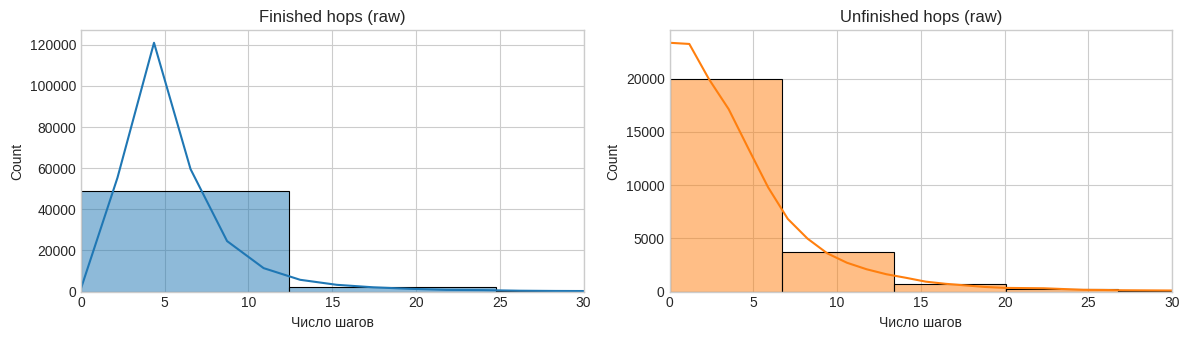

In [4]:
fin = paths[paths["finished"] == 1].copy()
unf = paths[paths["finished"] == 0].copy()

# Сравнение длин путей raw (с возвратами) и effective (без возвратов)
fin["n_hops_raw"] = fin["trace"].map(lambda s: len(s) - 1)
fin["n_hops_eff"] = fin["effective_path"].map(lambda s: len(s) - 1)
unf["n_hops_raw"] = unf["trace"].map(lambda s: len(s) - 1)

print("=== Finished paths (raw hops) ===")
print(fin["n_hops_raw"].describe())
print("\n=== Finished paths (effective hops) ===")
print(fin["n_hops_eff"].describe())

print("\n=== Распределение оценок сложности (rating) ===")
print(fin["rating"].value_counts(dropna=False).sort_index())

print("\n=== Причины прекращения игр (unfinished types) ===")
print(unf["type"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(fin["n_hops_raw"], bins=35, ax=axes[0], color="tab:blue", kde=True)
axes[0].set_title("Finished hops (raw)")
axes[0].set_xlabel("Число шагов")
axes[0].set_xlim(0, 30)

sns.histplot(unf["n_hops_raw"], bins=35, ax=axes[1], color="tab:orange", kde=True)
axes[1].set_title("Unfinished hops (raw)")
axes[1].set_xlabel("Число шагов")
axes[1].set_xlim(0, 30)

plt.tight_layout()
plt.show()


## 3. Топ промежуточных статей и статей-ловушек (Drop-off)


=== TOP-20 промежуточных статей ===
   9721  United_States
   4598  Europe
   4212  United_Kingdom
   3449  England
   3365  Earth
   2960  Africa
   2367  World_War_II
   1922  North_America
   1780  Animal
   1764  Germany
   1758  Mammal
   1733  Human
   1680  France
   1509  Science
   1447  English_language
   1441  Computer
   1422  Periodic_table
   1370  Atlantic_Ocean
   1343  Plant
   1325  Agriculture

=== TOP-20 статей отказа (Drop-off) ===
    660  United_States
    299  United_Kingdom
    285  England
    278  Brain
    202  Theatre
    200  Europe
    168  Mammal
    167  India
    156  Earth
    155  Africa
    153  France
    146  Asteroid
    144  Animal
    129  Pyramid
    127  World_War_II
    122  North_America
    120  Human
    114  Batman
    113  Plant
    104  English_language

=== TOP-15 статей по Drop-off Rate (>= 50 визитов) ===
  49.18%  Wikipedia_Text_of_the_GNU_Free_Documentation_License (визитов: 122)
  29.58%  Canadian_Senate (визитов: 71)
  19.25%  

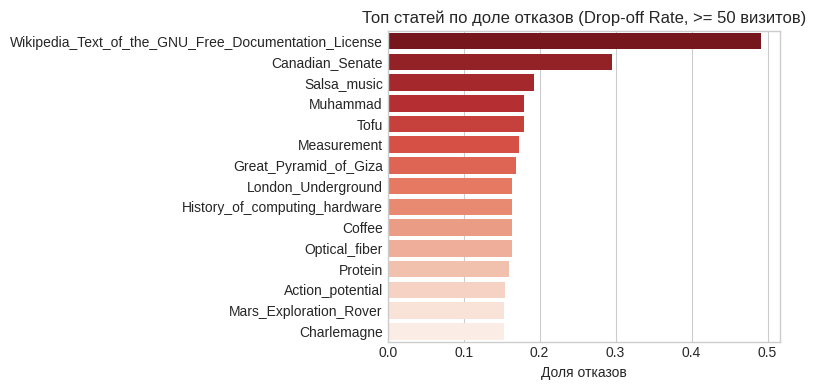

In [5]:
# 1. Топ промежуточных статей (без старта и финиша)
inter = Counter()
for seq in fin["trace"]:
    inter.update(seq[1:-1])
print("=== TOP-20 промежуточных статей ===")
for name, c in inter.most_common(20):
    print(f"  {c:5d}  {name}")

# 2. Топ статей, на которых бросают игру
drop = Counter()
for seq in unf["trace"]:
    if len(seq) > 0:
        drop[seq[-1]] += 1
print("\n=== TOP-20 статей отказа (Drop-off) ===")
for name, c in drop.most_common(20):
    print(f"  {c:5d}  {name}")

# 3. Нормализованный drop-off rate (доля отказов при >= 50 визитах)
visits = Counter()
for seq in list(fin["trace"]) + list(unf["trace"]):
    visits.update(seq)
ratio = {a: drop[a] / visits[a] for a in drop if visits[a] >= 50}
top_ratio = sorted(ratio.items(), key=lambda x: -x[1])[:15]

print("\n=== TOP-15 статей по Drop-off Rate (>= 50 визитов) ===")
for a, r in top_ratio:
    print(f"  {r:5.2%}  {a} (визитов: {visits[a]})")

# Барплот нормализованных отказов
top_drop_df = pd.DataFrame(top_ratio, columns=["article", "drop_rate"])
plt.figure(figsize=(8, 4))
sns.barplot(data=top_drop_df, x="drop_rate", y="article", hue="article", palette="Reds_r", legend=False)
plt.title("Топ статей по доле отказов (Drop-off Rate, >= 50 визитов)")
plt.xlabel("Доля отказов")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 4. Свойства графа: связность, диаметр и степенной закон


Плотность графа (density):       0.005657
Число слабо связных компонент:   14
Размер гигантской компоненты:    4,589 (99.67%)


Среднее кратчайшее расстояние:   3.21
Медиана расстояний:              3
Диаметр (приближённо):           8

=== ТОП-5 ХАБОВ ПО ИСХОДЯЩЕЙ СТЕПЕНИ (Out-degree) ===
                                out_degree  in_degree  pagerank
article                                                        
United_States                          294       1551  0.009562
Driving_on_the_left_or_right           255          0  0.000033
List_of_countries                      244         63  0.000364
List_of_circulating_currencies         236          8  0.000228
List_of_sovereign_states               216         43  0.000231

=== ТОП-5 АВТОРИТЕТОВ ПО ВХОДЯЩЕЙ СТЕПЕНИ (In-degree) ===
                in_degree  out_degree  pagerank
article                                        
United_States        1551         294  0.009562
United_Kingdom        972         168  0.006232
France                959          85  0.006420
Europe                933         159  0.006337
World_War_II          751         119  0.0

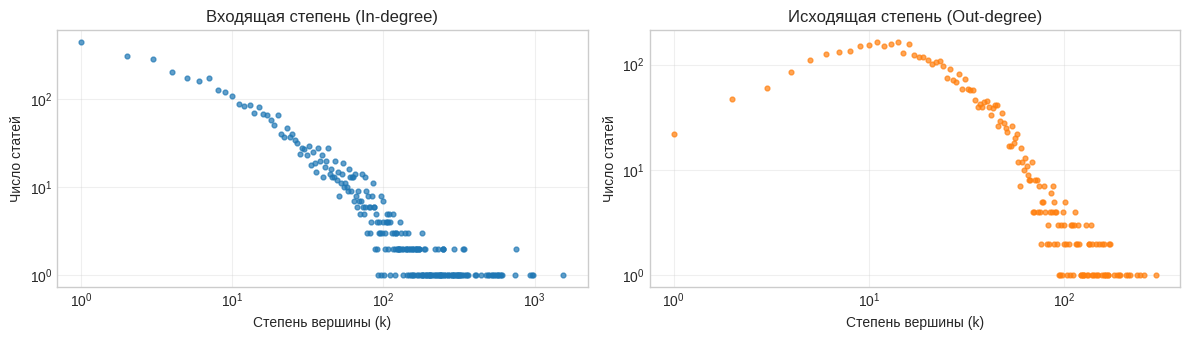

In [6]:
# Связность и компоненты
components = list(nx.weakly_connected_components(G))
giant_size = max(len(c) for c in components)
print(f"Плотность графа (density):       {nx.density(G):.6f}")
print(f"Число слабо связных компонент:   {len(components)}")
print(f"Размер гигантской компоненты:    {giant_size:,} ({giant_size / G.number_of_nodes():.2%})")

# Оценка диаметра и среднего расстояния (BFS на выборке из 600 узлов)
random.seed(42)
sample_nodes = random.sample(list(G.nodes), 600)
approx_distances = []
for src in sample_nodes:
    dists = nx.single_source_shortest_path_length(G, src)
    approx_distances.extend(dists.values())
approx_distances = np.array(approx_distances)
print(f"Среднее кратчайшее расстояние:   {approx_distances.mean():.2f}")
print(f"Медиана расстояний:              {np.median(approx_distances):.0f}")
print(f"Диаметр (приближённо):           {approx_distances.max()}")

# Топ хабы и PageRank
print("\n=== ТОП-5 ХАБОВ ПО ИСХОДЯЩЕЙ СТЕПЕНИ (Out-degree) ===")
print(nodes.sort_values("out_degree", ascending=False)[["out_degree", "in_degree", "pagerank"]].head(5))

print("\n=== ТОП-5 АВТОРИТЕТОВ ПО ВХОДЯЩЕЙ СТЕПЕНИ (In-degree) ===")
print(nodes.sort_values("in_degree", ascending=False)[["in_degree", "out_degree", "pagerank"]].head(5))

print("\n=== ТОП-5 ПО PAGERANK ===")
print(nodes.sort_values("pagerank", ascending=False)[["pagerank", "in_degree", "out_degree"]].head(5))

# Степенное распределение степеней (log-log)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col, title, color in [
    (axes[0], "in_degree", "Входящая степень (In-degree)", "tab:blue"),
    (axes[1], "out_degree", "Исходящая степень (Out-degree)", "tab:orange"),
]:
    counts = Counter(nodes[col])
    xs = sorted(k for k in counts.keys() if k > 0)
    ys = [counts[x] for x in xs]
    ax.scatter(xs, ys, s=12, alpha=0.7, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Степень вершины (k)")
    ax.set_ylabel("Число статей")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Человеческий оверхед (Human paths vs Shortest paths)


=== Сравнение реального пути с кратчайшим ===
           shortest        actual         ratio
count  51306.000000  51306.000000  51306.000000
mean       2.846100      5.758761      2.030605
std        0.699601      4.680459      1.721314
min        1.000000      1.000000      1.000000
25%        2.000000      4.000000      1.333333
50%        3.000000      5.000000      1.666667
75%        3.000000      7.000000      2.333333
max        6.000000    434.000000    217.000000

Медианный оверхед: 1.67x

=== ТОП-15 САМЫХ ОБМАНЧИВЫХ ЦЕЛЕЙ (максимальный оверхед при >= 20 играх) ===
                      mean    median  count
target                                     
English_language  5.636364  1.500000     55
IPod              3.786458  2.833333     32
Police_state      3.658333  2.583333     20
Mango             3.615079  2.500000     42
ITunes            3.591667  2.550000     24
Juice             3.439583  2.500000     40
Love              3.407407  2.333333     27
Frog              3.34

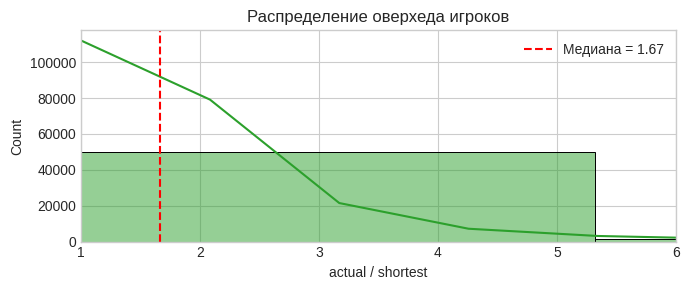

In [7]:
rows = []
for start, target, actual in zip(fin["start"], fin["target"], fin["n_hops_raw"]):
    if start in article_to_idx and target in article_to_idx:
        sp = D[article_to_idx[start], article_to_idx[target]]
        if sp > 0:
            rows.append({
                "start": start,
                "target": target,
                "shortest": sp,
                "actual": actual,
                "ratio": actual / sp
            })

cmp_df = pd.DataFrame(rows)
print("=== Сравнение реального пути с кратчайшим ===")
print(cmp_df[["shortest", "actual", "ratio"]].describe())
print(f"\nМедианный оверхед: {cmp_df['ratio'].median():.2f}x")

# Самые обманчивые цели (>= 20 партий)
print("\n=== ТОП-15 САМЫХ ОБМАНЧИВЫХ ЦЕЛЕЙ (максимальный оверхед при >= 20 играх) ===")
misleading = (
    cmp_df.groupby("target")["ratio"]
    .agg(["mean", "median", "count"])
    .query("count >= 20")
    .sort_values("mean", ascending=False)
    .head(15)
)
print(misleading)

# Гистограмма оверхеда
plt.figure(figsize=(7, 3))
sns.histplot(cmp_df["ratio"], bins=50, color="tab:green", kde=True)
plt.axvline(cmp_df["ratio"].median(), color="red", linestyle="--", label=f"Медиана = {cmp_df['ratio'].median():.2f}")
plt.xlabel("actual / shortest")
plt.xlim(1, 6)
plt.title("Распределение оверхеда игроков")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Динамика движения игроков (вывод West & Leskovec)


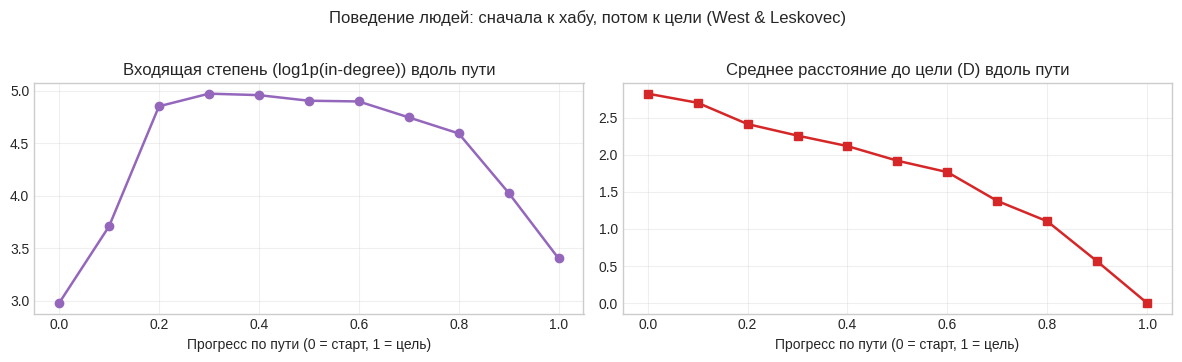

In [8]:
# Быстрые словари для оптимизации обращений вместо pandas .loc
in_deg_map = nodes["in_degree"].to_dict()
out_deg_map = nodes["out_degree"].to_dict()

# Анализируем успешные пути строго из Train
train_fin = fin[fin["split"] == "train"]

steps_norm = np.linspace(0, 1, 11)
avg_in_degrees = []
avg_log_in_degrees = []
avg_dists = []

for s in steps_norm:
    in_degs_at_s = []
    dists_at_s = []
    for trace, target in zip(train_fin["trace"], train_fin["target"]):
        if len(trace) < 2 or target not in article_to_idx:
            continue
        idx_step = int(round(s * (len(trace) - 1)))
        node = trace[idx_step]
        if node in in_deg_map:
            in_degs_at_s.append(in_deg_map[node])
        if node in article_to_idx:
            d = D[article_to_idx[node], article_to_idx[target]]
            if d >= 0:
                dists_at_s.append(d)
    avg_in_degrees.append(np.mean(in_degs_at_s))
    avg_log_in_degrees.append(np.mean(np.log1p(in_degs_at_s)))
    avg_dists.append(np.mean(dists_at_s))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(steps_norm, avg_log_in_degrees, marker="o", color="tab:purple", linewidth=1.8)
axes[0].set_title("Входящая степень (log1p(in-degree)) вдоль пути")
axes[0].set_xlabel("Прогресс по пути (0 = старт, 1 = цель)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(steps_norm, avg_dists, marker="s", color="tab:red", linewidth=1.8)
axes[1].set_title("Среднее расстояние до цели (D) вдоль пути")
axes[1].set_xlabel("Прогресс по пути (0 = старт, 1 = цель)")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Поведение людей: сначала к хабу, потом к цели (West & Leskovec)", y=1.02)
plt.tight_layout()
plt.show()
